In [ ]:
import qiskit
print(qiskit.__version__)

2.5.1


Matplotlib is building the font cache; this may take a moment.


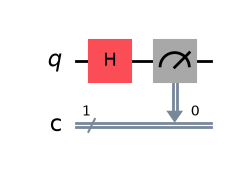

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 1 qubit, 1 classical bit
qc = QuantumCircuit(1, 1)

# Apply Hadamard gate -> puts qubit into superposition
qc.h(0)

# Measure the qubit
qc.measure(0, 0)

# Draw the circuit visually
qc.draw('mpl')

{'1': 515, '0': 485}


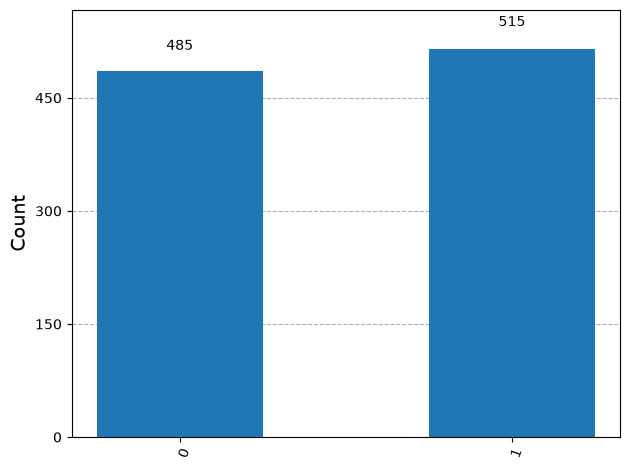

In [ ]:
simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()
print(counts)

from qiskit.visualization import plot_histogram
plot_histogram(counts)

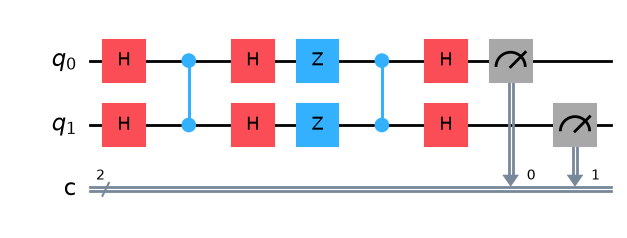

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# We're searching for the answer "11" among 4 possible 2-bit combinations: 00, 01, 10, 11
qc = QuantumCircuit(2, 2)

# STEP 1: Put both qubits into superposition
# This represents "checking all 4 possibilities at once"
qc.h(0)
qc.h(1)

# STEP 2: The Oracle - marks our target answer "11"
# A CZ (controlled-Z) gate flips the sign of the |11> state only,
# tagging it as "the answer" without revealing it yet
qc.cz(0, 1)

# STEP 3: The Diffuser - amplifies the marked answer's probability
# This is the "magic" step that makes the correct answer much
# more likely to appear when we measure
qc.h(0)
qc.h(1)
qc.z(0)
qc.z(1)
qc.cz(0, 1)
qc.h(0)
qc.h(1)

# STEP 4: Measure both qubits
qc.measure(0, 0)
qc.measure(1, 1)

# Draw the circuit
qc.draw('mpl')

{'11': 1000}


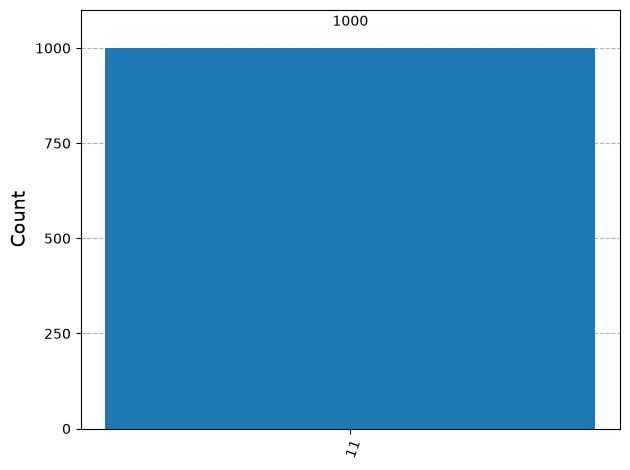

In [ ]:
simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()
print(counts)
plot_histogram(counts)

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(1)

# Apply gates
qc.h(0)
qc.x(0)
qc.y(0)
qc.z(0)
qc.h(0)

qc.x(0)
qc.h(0)
qc.z(0)
qc.y(0)

# Display circuit
print(qc.draw())

# Calculate final quantum state
state = Statevector.from_instruction(qc)

print("Final quantum state:")
print(state)